# 10-FreeRTOS软件定时器原理、API与应用


## 1. 本篇内容与学习目标

本篇是《FreeRTOS 从入门到实战》十七篇笔记中的第10篇，对应 `15软件定时器.pptx`，原课主题为**软件定时器**。

课件先区分硬件定时器和软件定时器，再说明 FreeRTOS 软件定时器依赖 SysTick 与定时器服务任务的工作方式，最后通过按键控制完成定时器的创建、启动、停止和删除。

| 课件主线 | 本篇学习内容 |
|---|---|
| 定时器分类 | 硬件定时器和软件定时器的基础、精度与适用场景 |
| 工作原理 | SysTick 计数、定时器服务任务和回调函数 |
| 基础 API | `xTimerCreate`、`xTimerStart`、`xTimerStop`、`xTimerDelete` |
| 工程应用 | 多定时器 ID、按键控制流程、配置和回调限制 |

本篇以课件第1—17页为教学内容，第18页为品牌结束页。PPT中的代码和参数按原课整理；没有把课件未展示的开发板型号、按键宏或 UART 细节补写成确定事实。


## 2. 定时器的两种形态

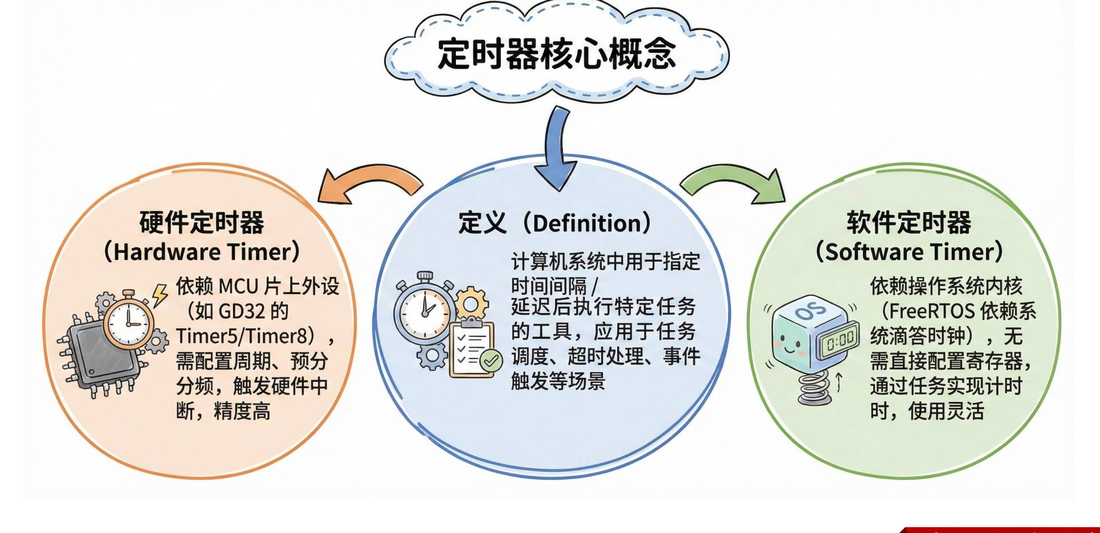

定时器的共同目标是：经过指定时间间隔后触发某个动作。FreeRTOS 课程把它分成两类：

| 对比维度 | 硬件定时器 | FreeRTOS 软件定时器 |
|---|---|---|
| 依赖基础 | MCU 片上定时器/计数器等独立外设 | FreeRTOS 内核、SysTick 和定时器服务任务 |
| 配置方式 | 配置周期、预分频、硬件中断寄存器 | 调用 FreeRTOS API，以 tick 设置周期 |
| 触发方式 | 硬件中断触发 | 定时器服务任务调用回调函数 |
| 时间特性 | 适合高精度、低抖动场景 | 受 tick 分辨率和任务调度影响，精度中等 |
| 灵活性 | 配置较固定，硬件资源有限 | 可动态创建、启动、停止和删除多个定时器 |
| 典型应用 | PWM、精确采样、硬实时外设控制 | 周期日志、超时处理、普通状态检查和延时通知 |

软件定时器的“软件”指它不需要为每个定时器单独占用一个 MCU 硬件定时器外设。它仍然需要系统 tick 作为时间基准，因此不能把软件定时器当成微秒级硬件定时器使用。


## 3. 软件定时器的实现原理

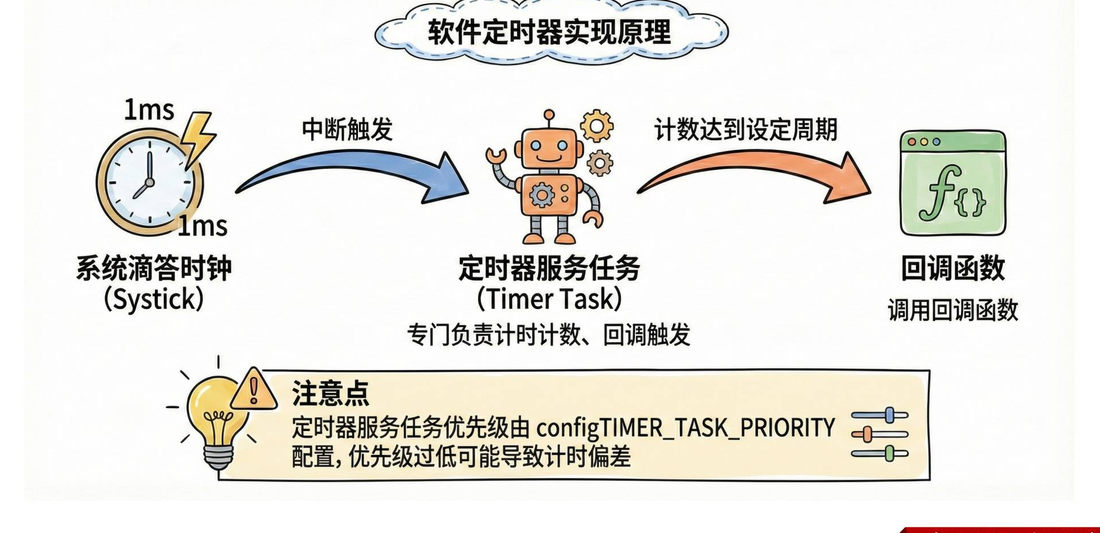

课件给出的流程可以概括为：

```text
SysTick 每个 tick 到来
        ↓
FreeRTOS 更新 tick 并判断定时器是否到期
        ↓
定时器命令进入定时器服务任务处理
        ↓
计数达到设定周期后调用回调函数
```

软件定时器的回调函数运行在 **Timer Service Task（定时器服务任务）** 上下文中，不是在硬件中断里直接执行。回调函数因此能够使用一部分任务级 API，但仍必须保持短小，不能在其中调用会永久阻塞或长时间占用 CPU 的操作。

定时器服务任务的优先级由 `configTIMER_TASK_PRIORITY` 配置。若该任务优先级过低，其他高优先级任务长期运行时，回调可能晚于理论到期时间执行；若优先级过高，又可能影响普通任务的响应。因此应结合回调耗时和系统任务优先级进行配置。

课件把软件定时器的精度标为“中等”。这里的周期是 tick 的整数倍，实际回调时间还会受调度、临界区和其他任务影响。它适合“到期后尽快处理”的任务级动作，不适合要求严格硬件时序的 PWM 或高速采样。


## 4. 创建定时器：`xTimerCreate`

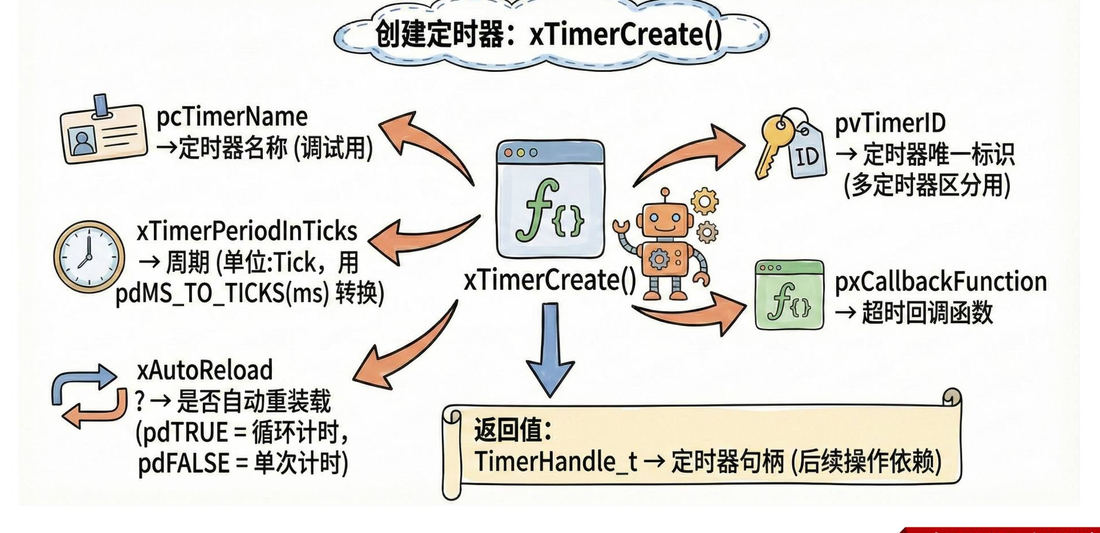

`xTimerCreate()` 负责建立软件定时器对象，成功后返回 `TimerHandle_t` 句柄，失败返回 `NULL`。课件展示的主要参数如下：

```c
TimerHandle_t xTimerCreate(
    const char * const pcTimerName,
    TickType_t xTimerPeriodInTicks,
    UBaseType_t uxAutoReload,
    void * pvTimerID,
    TimerCallbackFunction_t pxCallbackFunction
);
```

各参数的含义：

| 参数 | 作用 |
|---|---|
| `pcTimerName` | 定时器名称，主要用于调试和查看 |
| `xTimerPeriodInTicks` | 定时周期，单位是 tick；可用 `pdMS_TO_TICKS(ms)` 从毫秒换算 |
| `uxAutoReload` | 是否自动重载；`pdTRUE` 周期触发，`pdFALSE` 单次触发 |
| `pvTimerID` | 用户自定义 ID，便于多个定时器共用一个回调函数 |
| `pxCallbackFunction` | 定时器到期后由服务任务调用的回调函数 |

返回的 `TimerHandle_t` 是后续启动、停止、删除和读取 ID 的依据。创建失败时必须检查 `NULL`，不能把无效句柄传给后续 API。

周期使用 tick 而不是直接使用微秒或毫秒。比如系统 tick 周期为1ms时，`pdMS_TO_TICKS(100)` 通常换算为100个 tick；实际工程仍应确认 `configTICK_RATE_HZ` 和整数换算结果。


## 5. 启动定时器：`xTimerStart`

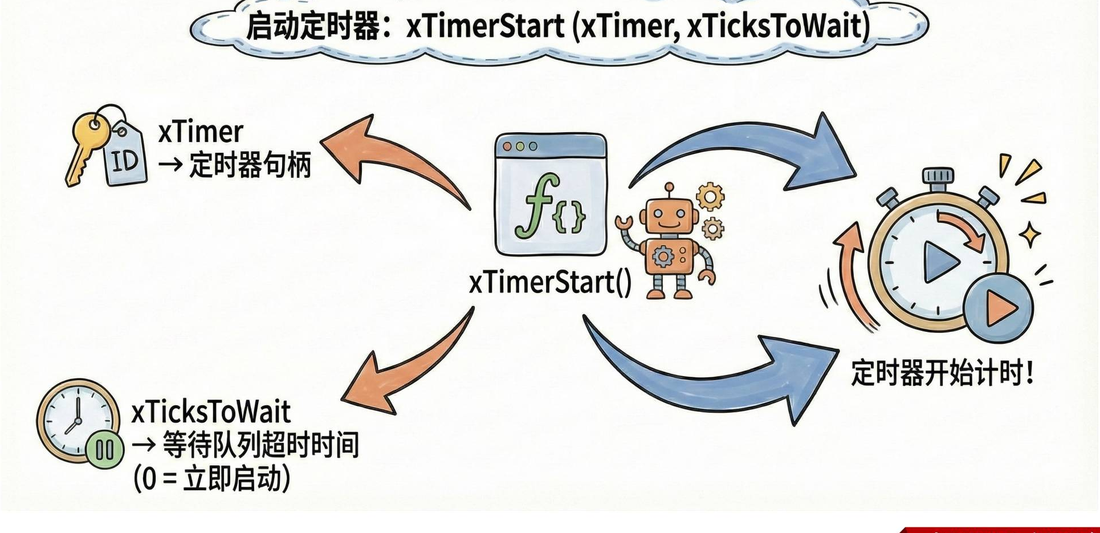

创建定时器后，必须调用 `xTimerStart()` 才会真正开始计时：

```c
BaseType_t xTimerStart(TimerHandle_t xTimer, TickType_t xTicksToWait);
```

`xTimer` 是 `xTimerCreate()` 返回的句柄；`xTicksToWait` 是向定时器命令队列发送“启动”命令时允许等待的 tick 数。课件强调：`xTicksToWait == 0` 表示不等待，命令无法立即进入队列时直接返回；使用非零值时，调用者可能等待队列空间。

一个基本创建和启动片段如下：

```c
static TimerHandle_t timer1Handler;

timer1Handler = xTimerCreate(
    "timer1",
    pdMS_TO_TICKS(1000),
    pdTRUE,
    (void *)1,
    timer_callback
);

if (timer1Handler != NULL) {
    BaseType_t ok = xTimerStart(timer1Handler, 0);
    configASSERT(ok == pdPASS);
}
```

在调度器启动前创建并启动定时器时，应按照工程初始化顺序确认定时器服务任务已经能够处理命令；在任务运行期间调用则要给命令队列留出合理的等待策略。无论何时，都要检查返回值并处理队列满或对象无效等失败情况。


## 6. 停止和删除：`xTimerStop`、`xTimerDelete`

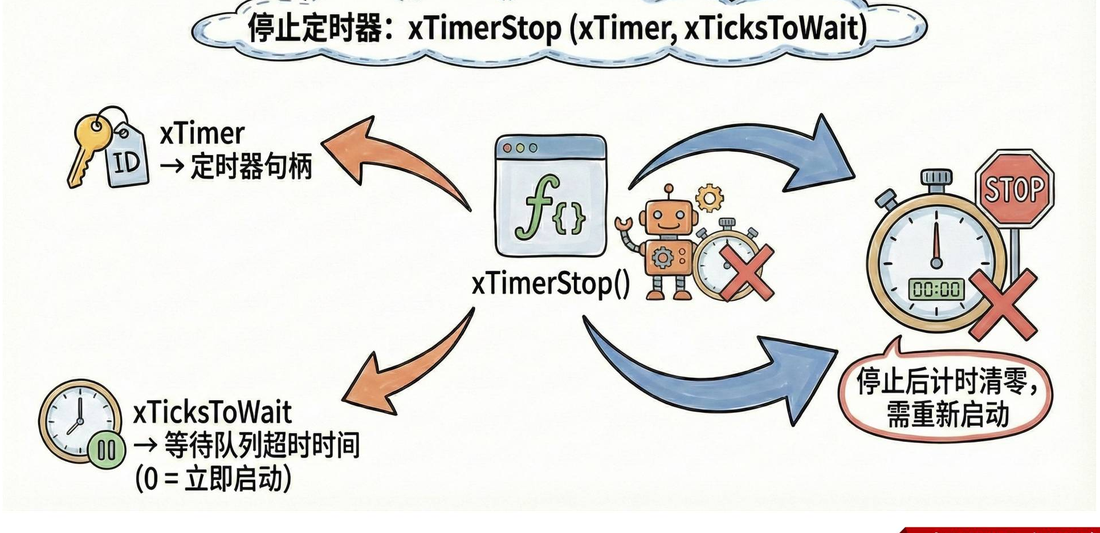

停止定时器：

```c
BaseType_t xTimerStop(TimerHandle_t xTimer, TickType_t xTicksToWait);
```

停止后，定时器不再继续计时；如果要再次使用，需要重新调用 `xTimerStart()`。`xTimerStop()` 不会释放定时器对象，也不会让句柄自动变成 `NULL`。

删除定时器：

```c
BaseType_t xTimerDelete(TimerHandle_t xTimer, TickType_t xTicksToWait);
```

删除后，对象占用的内核资源由 FreeRTOS 回收，原句柄不能继续使用。课件给出的工程习惯是删除成功后手动置空：

```c
if (xTimerDelete(timer1Handler, 0) == pdPASS) {
    timer1Handler = NULL;  // 防止野指针式的再次访问
}
```

停止和删除的第二个参数仍然是向定时器命令队列发送命令时的等待时间。它不是“定时器停止后再等待多久”，也不是定时器周期。

删除前应确认没有其他代码并发使用同一个句柄。若一个按键回调、任务或状态机都能操作定时器，需要规定句柄所有权和状态，否则容易出现重复删除、启动已删除对象或回调与删除交错的问题。


## 7. 回调函数与多定时器 ID

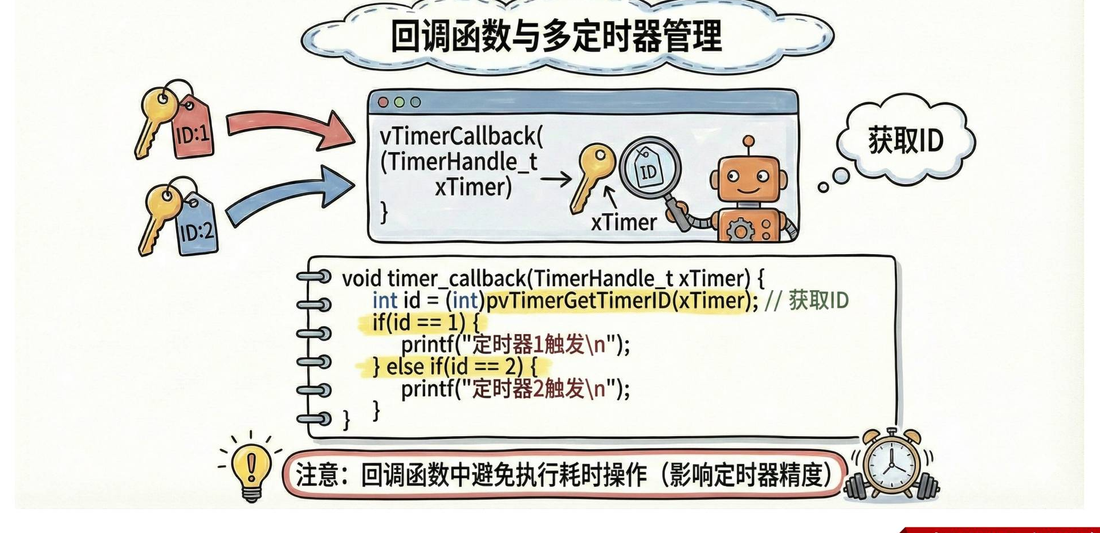

定时器到期后，FreeRTOS 调用创建时传入的回调函数。典型回调签名为：

```c
void timer_callback(TimerHandle_t xTimer)
{
    int id = (int)(intptr_t)pvTimerGetTimerID(xTimer);

    if (id == 1) {
        printf("定时器1触发\\n");
    } else if (id == 2) {
        printf("定时器2触发\\n");
    }
}
```

多个定时器可以共享一个回调函数，通过 `pvTimerGetTimerID(xTimer)` 取得创建时传入的 `pvTimerID` 再分支处理。定时器名称也可以帮助调试，但名称不适合作为高效的运行时分派键。

回调函数由定时器服务任务串行执行。回调中应避免：

- 调用 `vTaskDelay()` 或执行可能长时间阻塞的等待；
- 做大量计算、长时间打印或调用不确定耗时的函数；
- 直接假设自己运行在硬件 ISR 上下文；
- 删除当前正在使用的句柄后继续访问它。

如果回调需要完成复杂工作，应发送通知、队列消息或事件给专门任务，让定时器服务任务尽快返回。这样可以减少一个回调阻塞其他软件定时器的风险。


## 8. 按键控制定时器的完整流程

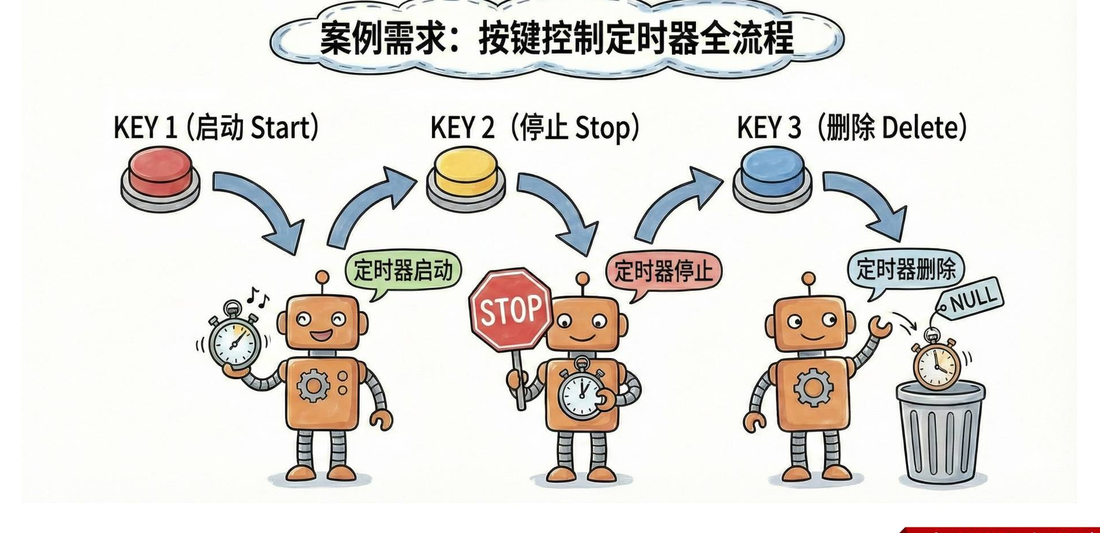

课件案例把三个按键映射到三个生命周期操作：

| 按键 | 动作 | 关键检查 |
|---|---|---|
| `KEY1` | `xTimerStart(timer1Handler, 0)` | 句柄必须非 `NULL` |
| `KEY2` | `xTimerStop(timer1Handler, 0)` | 定时器可以已停止，仍应检查返回值 |
| `KEY3` | `xTimerDelete(timer1Handler, 0)` | 删除成功后把句柄置为 `NULL` |

对应的按键回调可以写成：

```c
void bsp_key_press_callback(KEY key)
{
    if (key == KEY1 && timer1Handler != NULL) {
        xTimerStart(timer1Handler, 0);
    } else if (key == KEY2 && timer1Handler != NULL) {
        xTimerStop(timer1Handler, 0);
    } else if (key == KEY3 && timer1Handler != NULL) {
        if (xTimerDelete(timer1Handler, 0) == pdPASS) {
            timer1Handler = NULL;
        }
    }
}
```

这里保留课件的流程含义，没有假定 `KEY` 枚举或按键驱动名称一定与工程完全相同。若按键回调本身运行在硬件 ISR 中，不能直接调用普通任务版本的定时器 API，应使用对应的 `FromISR` 版本，并遵守中断优先级限制；课件示例更接近任务级按键回调。


## 9. 配置：开启软件定时器和服务任务

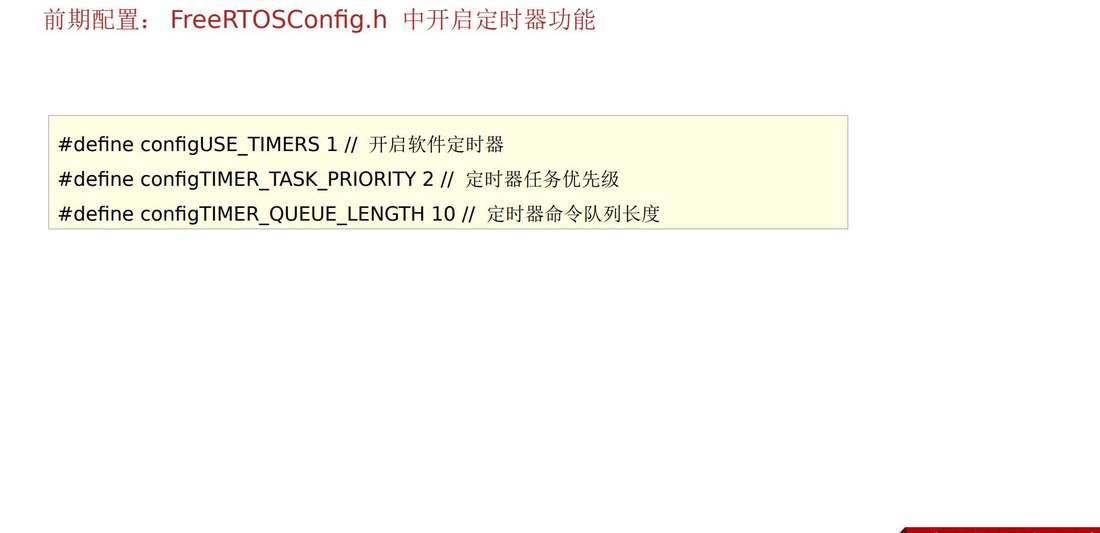

使用软件定时器前，需要在 `FreeRTOSConfig.h` 中开启相关配置。课件给出的核心选项为：

```c
#define configUSE_TIMERS             1   // 开启软件定时器
#define configTIMER_TASK_PRIORITY    2   // 定时器服务任务优先级
#define configTIMER_QUEUE_LENGTH     10  // 定时器命令队列长度
```

三个配置分别决定：是否编译和创建软件定时器功能、定时器服务任务的优先级，以及暂存启动/停止/删除等命令的队列容量。

`configTIMER_QUEUE_LENGTH` 不是“同时可以创建的定时器数量”。它表示定时器命令队列的长度；如果短时间内集中发送大量命令，队列可能暂时变满，调用者应根据 API 返回值和等待时间处理这种情况。

软件定时器对象本身仍需要内存。使用动态创建时，相关控制块来自 FreeRTOS 的动态内存策略；如果工程使用静态定时器 API，则需提供对应的静态存储。课件本篇主要讲 `xTimerCreate()`，因此不把静态创建接口扩展成课程中已经展示的内容。


## 10. 精度、生命周期和使用边界

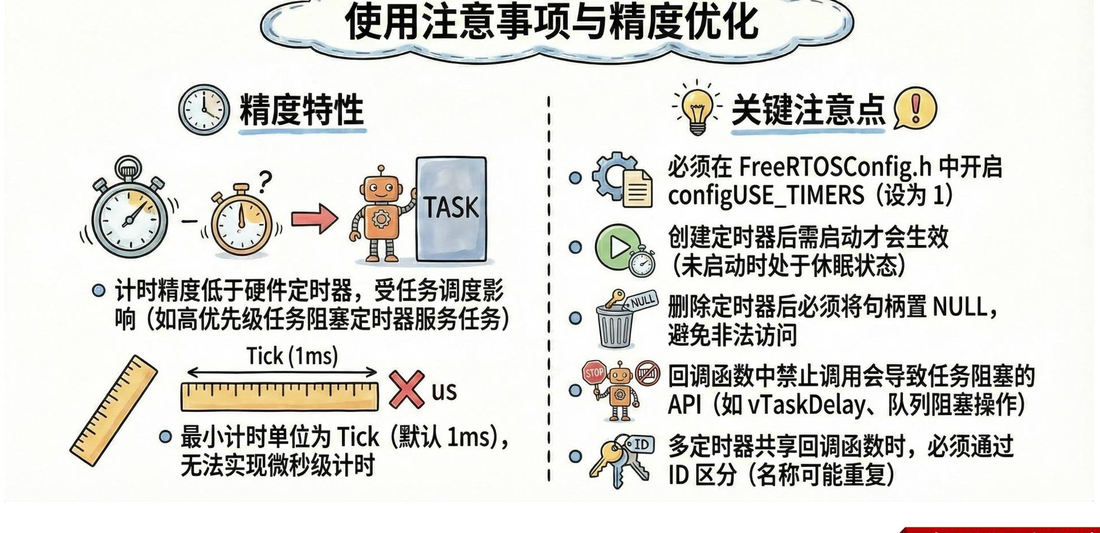

### 精度不是微秒级保证

软件定时器的最小时间单位是系统 tick。课件以默认1ms tick作为说明，实际工程应以 `configTICK_RATE_HZ` 计算：

```text
tick 周期 = 1 / configTICK_RATE_HZ
定时周期 = xTimerPeriodInTicks × tick 周期
```

周期只能按 tick 整数表达，并会受到定时器服务任务优先级、其他任务运行时间、临界区和调度延迟的影响。需要高精度或严格边沿时序时，应选择硬件定时器。

### 生命周期要完整

软件定时器的基本状态链是：

```text
xTimerCreate → xTimerStart → 回调执行 → xTimerStop / xTimerDelete
```

自动重载定时器每次回调后继续等待下一个周期；单次定时器到期后不会自动重新开始。删除后必须放弃旧句柄，避免野指针。

### 回调保持短小

多个定时器共享一个服务任务，某个回调执行过久会拖慢其他定时器的回调。回调中不放阻塞操作、长时间打印或大段业务逻辑；把复杂工作转交给普通任务。

### 多定时器要有分派规则

多个定时器共用回调时，使用 `pvTimerGetTimerID()` 区分来源。ID 的生命周期和类型转换要明确，不要把已经释放对象的地址作为 ID 长期保存。


## 11. 本课要点与工程核对

第17页总结了本课的核心：硬件定时器精度高，软件定时器灵活；FreeRTOS 软件定时器依赖 SysTick 和定时器服务任务；常用流程是创建、启动、回调、停止或删除；多定时器通过 ID 区分；普通周期需求使用软件定时器，高精度需求选择硬件定时器。

在课程工程中可以按以下顺序核对：

1. 检查 `configUSE_TIMERS` 是否为1，确认 `configTIMER_TASK_PRIORITY` 和 `configTIMER_QUEUE_LENGTH` 与系统任务规模匹配。
2. 检查每次 `xTimerCreate()` 的句柄、周期、自动重载标志、ID 和回调函数，处理返回 `NULL` 的情况。
3. 检查创建后是否明确调用 `xTimerStart()`；停止后若要复用，是否再次启动。
4. 删除定时器后立即把句柄置为 `NULL`，并确认其他任务或回调不会继续使用旧句柄。
5. 检查回调函数没有阻塞、长时间打印或不可控的耗时操作；复杂业务通过任务、队列或通知异步处理。
6. 根据 `configTICK_RATE_HZ` 计算实际周期，不能把 tick 直接当成固定毫秒，更不能把软件定时器当作微秒级硬件定时器。
7. 如果按键处理运行在 ISR 中，改用合法的 `FromISR` API；若运行在任务或驱动回调中，则确认调用上下文和句柄访问已经串行化。

本篇内容依据 `15软件定时器.pptx` 的教学页整理，未进行开发板编译、下载或运行，也未伪造定时器回调时刻和按键实测结果。
